Importing Libarires here

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_auc_score, average_precision_score,
                             RocCurveDisplay, PrecisionRecallDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

Loading the preprocessed data

In [ ]:
DATA_PATH = "H2_Cleaned_classification.csv"
TARGET = "IsCanceled"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (48989, 27)


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,MarketSegment,DistributionChannel,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,ReservedRoomType,AssignedRoomType,BookingChanges,DepositType,DaysInWaitingList,CustomerType,ADR,TotalOfSpecialRequests,HasCompany
0,1,88,2015,July,27,1,0,4,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,0,Transient,76.5,1,0
1,1,65,2015,July,27,1,0,4,1,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,0,Transient,68.0,1,0
2,1,92,2015,July,27,1,2,4,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,0,Transient,76.5,2,0
3,1,100,2015,July,27,2,0,2,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,0,Transient,76.5,1,0
4,1,79,2015,July,27,2,0,3,2,0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,0,Transient,76.5,1,0


In [ ]:
# Quick sanity checks
print("Missing values per column (non-zero only):")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nClass balance:")
print(df[TARGET].value_counts(normalize=True).round(3))

Missing values per column (non-zero only):
Series([], dtype: int64)

Class balance:
IsCanceled
0    0.707
1    0.293
Name: proportion, dtype: float64


Features / target

reading the columns of our df

In [ ]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

categorical = X.select_dtypes(include=["object", "category", "string", "bool"]).columns.tolist()
numeric = [c for c in X.columns if c not in categorical]

print(f"{len(numeric)} numeric features, {len(categorical)} categorical features")
print("Categorical:", categorical)

17 numeric features, 9 categorical features
Categorical: ['ArrivalDateMonth', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'CustomerType']


Train / test split (stratified)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (39191, 26)  Test: (9798, 26)


Model pipeline

In [ ]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), numeric),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                           min_frequency=0.005))]), categorical),
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
])

Baseline

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('sc',
                                                                   StandardScaler())]),
                                                  ['LeadTime',
                                                   'ArrivalDateYear',
                                                   'ArrivalDateWeekNumber',
                                                   'ArrivalDateDayOfMonth',
                                                   'StaysInWeekendNights',
                                                   'StaysInWeekNights',
                                                   'Adults', 'Children',
                                                   'Babies', 'IsRepeatedGuest',
                                                   'PreviousCancellations',
                                                   'PreviousBoo...
                                                  Pipeline(steps=[('imp',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('oh',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=0.005))]),
                                                  ['ArrivalDateMonth', 'Meal',
                                                   'Country', 'MarketSegment',
                                                   'DistributionChannel',
                                                   'ReservedRoomType',
                                                   'AssignedRoomType',
                                                   'DepositType',
                                                   'CustomerType'])])),
                ('clf', LogisticRegression(max_iter=3000, random_state=42))])

Cross-validation results

In [ ]:
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}

cv_res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

cv_table = pd.DataFrame({
    "mean": {m: cv_res[f"test_{m}"].mean() for m in scoring},
    "std":  {m: cv_res[f"test_{m}"].std()  for m in scoring},
}).round(4)
cv_table

,mean,std
accuracy,0.7672,0.0016
precision,0.6596,0.0043
recall,0.4239,0.0077
f1,0.5160,0.0057
roc_auc,0.7959,0.0023
pr_auc,0.6239,0.0055


In [ ]:
# Per-fold detail
pd.DataFrame({m: cv_res[f"test_{m}"] for m in scoring},
             index=[f"Fold {i+1}" for i in range(5)]).round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
Fold 1,0.7655,0.6529,0.4260,0.5156,0.7937,0.6212
Fold 2,0.7701,0.6651,0.4327,0.5243,0.7991,0.6337
Fold 3,0.7661,0.6609,0.4135,0.5087,0.7966,0.6221
Fold 4,0.7673,0.6567,0.4307,0.5203,0.7929,0.6253
Fold 5,0.7669,0.6625,0.4164,0.5114,0.7970,0.6172


Final test-set performance
Metrics that were asked to be shown from the Project documentation

In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

test_metrics = pd.Series({
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
    "PR-AUC":    average_precision_score(y_test, y_prob),
}, name="Test").round(4)
display(test_metrics.to_frame())

print(classification_report(y_test, y_pred, target_names=["Not canceled", "Canceled"]))

,Test
Accuracy,0.7596
Precision,0.6397
Recall,0.4102
F1-score,0.4999
ROC-AUC,0.7890
PR-AUC,0.6154


              precision    recall  f1-score   support

Not canceled       0.79      0.90      0.84      6929
    Canceled       0.64      0.41      0.50      2869

    accuracy                           0.76      9798
   macro avg       0.71      0.66      0.67      9798
weighted avg       0.74      0.76      0.74      9798



Train vs test (overfitting check)

In [ ]:
print(f"Train accuracy: {model.score(X_train, y_train):.4f}")
print(f"Test accuracy:  {model.score(X_test, y_test):.4f}")

Train accuracy: 0.7687
Test accuracy:  0.7596


Confusion matrix

TN=6266  FP=663  FN=1692  TP=1177


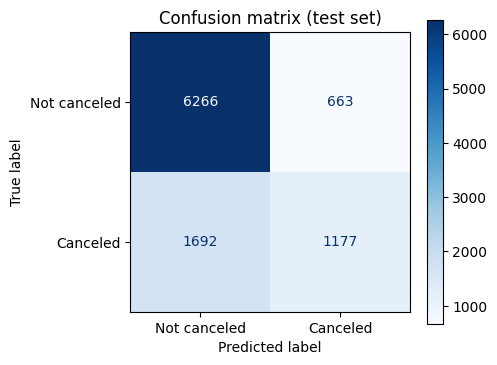

In [ ]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Not canceled", "Canceled"]).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

ROC and Precision-Recall curves

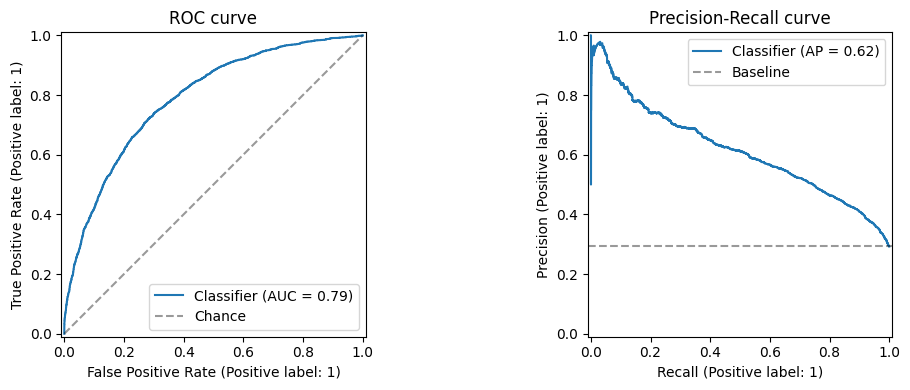

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4, label="Chance")
axes[0].set_title("ROC curve"); axes[0].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].axhline(y_test.mean(), color="k", ls="--", alpha=0.4, label="Baseline")
axes[1].set_title("Precision-Recall curve"); axes[1].legend()

plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=150)
plt.show()

Interpreting the model (coefficients)
Features are standardized, so coefficient sizes are comparable. Positive = higher cancellation risk.

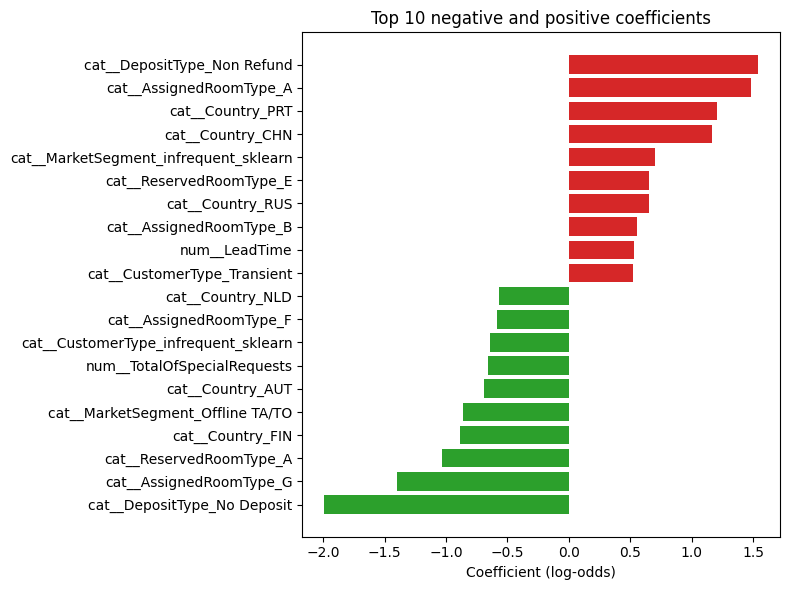

In [ ]:
names = model.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=names).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=["tab:green" if v < 0 else "tab:red" for v in top.values])
ax.set_title("Top 10 negative and positive coefficients")
ax.set_xlabel("Coefficient (log-odds)")
plt.tight_layout()
plt.savefig("coefficients.png", dpi=150)
plt.show()

Summary table (CV vs. test)

In [ ]:
summary = pd.DataFrame({
    "CV mean": cv_table["mean"],
    "CV std": cv_table["std"],
    "Test": test_metrics.rename(index={"F1-score": "f1", "Accuracy": "accuracy", "Precision": "precision",
                                       "Recall": "recall", "ROC-AUC": "roc_auc", "PR-AUC": "pr_auc"}),
}).round(4)
summary

,CV mean,CV std,Test
accuracy,0.7672,0.0016,0.7596
precision,0.6596,0.0043,0.6397
recall,0.4239,0.0077,0.4102
f1,0.5160,0.0057,0.4999
roc_auc,0.7959,0.0023,0.7890
pr_auc,0.6239,0.0055,0.6154


Save the model

In [ ]:
import joblib

joblib.dump(model, "logreg_baseline.joblib")
print("saved: logreg_baseline.joblib")

saved: logreg_baseline.joblib
